In [49]:
# importing libraries
import numpy as np 
import seaborn as sns

import tensorflow
from tensorflow import keras
from keras.layers import Conv2D, Flatten, AveragePooling2D, Input, UpSampling2D, Conv2DTranspose
from keras import Sequential, Model
from keras.datasets import mnist

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train, x_test = x_train/255, x_test/255

## Encoder - Decoder

### Encoder

In [34]:
input_img = Input(shape=(28, 28, 1))

l1 = Conv2D(8, kernel_size=(3, 3), activation='tanh', padding='valid')(input_img)
p1 = AveragePooling2D(pool_size=(2,2), strides=2, padding='valid')(l1)

l2 = Conv2D(16, kernel_size=(3, 3), activation='relu', padding='valid')(p1)
p2 = AveragePooling2D(pool_size=(2, 2), strides=2, padding='valid')(l2)

encoder = Model(input_img, p2, name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_22 (InputLayer)          │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_25 (Conv2D)                   │ (None, 26, 26, 8)           │              80 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ average_pooling2d_6                  │ (None, 13, 13, 8)           │               0 │
│ (AveragePooling2D)                   │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_26 (Conv2D)                   │ (None, 11, 11, 16)          │           1,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ average_pooling2d_7                  │ (None, 5, 5, 16)            │               0 │
│ (AveragePooling2D)                   │                             │                 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,248 (4.88 KB)

 Trainable params: 1,248 (4.88 KB)

 Non-trainable params: 0 (0.00 B)

### Decoder

In [44]:
dinput_img = Input(shape=(5, 5, 16))

d1 = Conv2D(16, kernel_size=(3, 3), activation='relu', padding='same')(dinput_img)
u1 = UpSampling2D(size=(2, 2))(d1)

d2 = Conv2D(8, kernel_size=(3, 3), activation='relu', padding='same')(u1)
u2 = UpSampling2D(size=(2, 2))(d2)

output = Conv2DTranspose(1, kernel_size=(9, 9), padding='valid', activation='sigmoid')(u2)

decoder = Model(dinput_img, output, name='decoder')
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_30 (InputLayer)          │ (None, 5, 5, 16)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_40 (Conv2D)                   │ (None, 5, 5, 16)            │           2,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_48 (UpSampling2D)      │ (None, 10, 10, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_41 (Conv2D)                   │ (None, 10, 10, 8)           │           1,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_49 (UpSampling2D)      │ (None, 20, 20, 8)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose_25                  │ (None, 28, 28, 1)           │             649 │
│ (Conv2DTranspose)                    │                             │                 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,129 (16.13 KB)

 Trainable params: 4,129 (16.13 KB)

 Non-trainable params: 0 (0.00 B)

### AutoEncoder

In [45]:
autoencoder_output = decoder(encoder(input_img))

autoencoder = Model(input_img, autoencoder_output, name='auto_encoder')

In [46]:
autoencoder.compile(loss='mse', optimizer='adam')

In [47]:
history = autoencoder.fit(x_train, x_train, batch_size=1000, validation_data=(x_test, x_test), epochs=15)

Epoch 1/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 7s 100ms/step - loss: 0.1295 - val_loss: 0.0569
Epoch 2/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 95ms/step - loss: 0.0376 - val_loss: 0.0249
Epoch 3/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 93ms/step - loss: 0.0217 - val_loss: 0.0187
Epoch 4/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 93ms/step - loss: 0.0177 - val_loss: 0.0159
Epoch 5/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 94ms/step - loss: 0.0153 - val_loss: 0.0140
Epoch 6/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 93ms/step - loss: 0.0137 - val_loss: 0.0126
Epoch 7/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 96ms/step - loss: 0.0125 - val_loss: 0.0116
Epoch 8/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 93ms/step - loss: 0.0115 - val_loss: 0.0107
Epoch 9/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 93ms/step - loss: 0.0107 - val_loss: 0.0100
Epoch 10/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 93ms/step - loss: 0.0101 - val_loss: 0.0094
Epoch 11/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 94ms/step - loss: 0.0096 - val_loss: 0.0089
Epoch 12/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 94ms/step - loss: 0.

<Axes: >

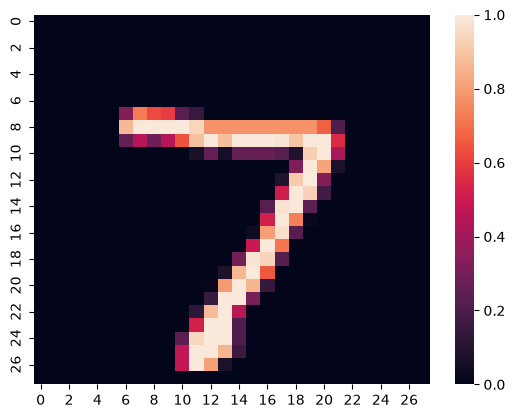

In [50]:
sns.heatmap(x_test[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


<Axes: >

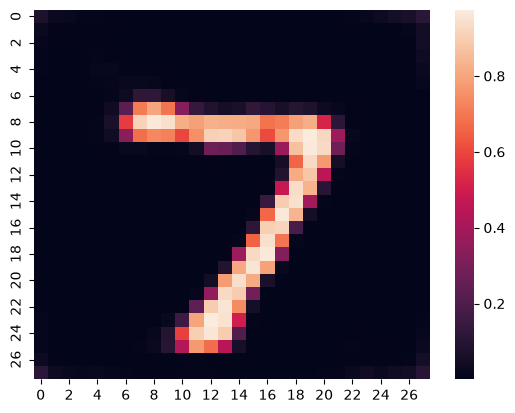

In [62]:
sns.heatmap(autoencoder.predict(x_test[:1]).reshape(28, 28))